# Caracterización integral de los CTN · corredor MEX-095D
**Equipo 20 · Proyecto ML–SEDP (Green Stops)**

Este notebook lleva el modelo de tránsito del Avance 5 al entregable que pide el sponsor:
**CTN → predicción → confianza → explicación → significado de ingeniería**, integrando las tres dimensiones de su presentación:

| Dimensión | Pregunta del sponsor | Fuentes |
|---|---|---|
| **Movilidad** | ¿Dónde existe flujo vehicular y necesidad potencial de recarga? | SICT Datos Viales, RNC 2025, modelo del Avance 5 |
| **Energía** | ¿Dónde coinciden recurso solar y demanda? | NASA POWER, composición vehicular y factor de hora pico de SICT |
| **Territorio** | ¿Qué condiciones agrícolas, ambientales y sociales rodean cada nodo? | INEGI Uso del Suelo y Vegetación Serie VII, Censo 2020 |

**Criterio científico (sponsor):** el resultado *caracteriza, compara, explica e identifica incertidumbre*; **no decide dónde construir**.

Secciones: 1) datos · 2) movilidad con enfoque combinado (ML + aforos) · 3) energía: demanda de recarga y potencial solar · 4) territorio · 5) arquetipos de nodos · 6) coincidencias, tensiones y vacíos · 7) conclusiones.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor, VotingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import tdpa_comun as tc
from tdpa_comun import TARGET, PreparadorSeguro, preparar_datos, detectar_log, invertir_log

%matplotlib inline
warnings.filterwarnings("ignore")
SEED = 20
ROOT = tc.encontrar_raiz()
P = ROOT / "03_PROCESSED"
OUT = ROOT / "06_RESULTS" / "CARACTERIZACION"
OUT.mkdir(parents=True, exist_ok=True)
CRS_M = "EPSG:6372"
CORTES = np.array([6641.0, 18448.0])      # categorías bajo/medio/alto del Avance 5 (terciles del TDPA de entrenamiento)
ETIQ = np.array(["bajo", "medio", "alto"])

## 1. Datos
- **CTN:** `FE_CTN_Prediction_Table_v3.csv` (variables de red, NASA POWER, uso de suelo, Censo, DENUE) y `06_RESULTS/AVANCE5/predicciones_ctn.csv` (TDPA del modelo final con intervalo calibrado).
- **Aforos del corredor:** los 23 aforos SICT de la MEX-095D (prueba externa del Avance 5), con su **composición vehicular** y su **factor K** (fracción del tránsito diario en la hora de máxima demanda), tomados de los PDF de Datos Viales.
- **Geometría del corredor:** `02_INTERIM/corridor_route.gpkg`, para ubicar los aforos en el mismo kilometraje (chainage) que los CTN.

In [2]:
ctn = pd.read_csv(P / "FE_CTN_Prediction_Table_v3.csv", low_memory=False)
ml = pd.read_csv(ROOT / "06_RESULTS" / "AVANCE5" / "predicciones_ctn.csv")
ctn = ctn.merge(ml[["ctn_id", "tdpa_estimado", "tdpa_p10", "tdpa_p90"]], on="ctn_id", how="left", validate="one_to_one")

tabla, train, test = preparar_datos(P / "FE_TOP_Model_Table_v2.csv")
modo_log, _ = detectar_log(train)
sitios = pd.read_csv(ROOT / "02_INTERIM" / "datos_viales_sites.csv")
filas = pd.read_csv(ROOT / "02_INTERIM" / "datos_viales_rows.csv", low_memory=False)
k_por_km = (filas[(filas.ruta == "MEX-095D") & filas.has_tdpa.astype(bool)].groupby("KM")["K"].median())
af = test[["site_id", "KM", "lugar_base", "tdpa", "lat", "lon"]].merge(sitios[["site_id", "pct_B", "pct_C"]], on="site_id", how="left")
af["ligeros_pct"] = 100 - af.pct_B.fillna(0) - af.pct_C.fillna(0)
af["K"] = af.KM.map(k_por_km)

ruta = gpd.read_file(ROOT / "02_INTERIM" / "corridor_route.gpkg").to_crs(CRS_M).geometry.iloc[0]
def chainage(df):
    pts = gpd.GeoSeries(gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326").to_crs(CRS_M)
    return np.array([ruta.project(p) / 1000 for p in pts])
af["chainage_km"] = chainage(af)
af = af.sort_values("chainage_km").reset_index(drop=True)
check = np.abs(chainage(ctn) - ctn.chainage_km).max()
print(f"CTN: {len(ctn)} | aforos del corredor: {len(af)} | longitud del corredor: {ruta.length / 1000:.0f} km")
print(f"Control: diferencia máxima entre el chainage proyectado y el de la tabla de CTN = {check:.2f} km")
display(af[["chainage_km", "KM", "lugar_base", "tdpa", "ligeros_pct", "K"]].round(3))

Tabla maestra (1075, 279) | train 703 | test externo 23 | purgados 349


CTN: 46 | aforos del corredor: 23 | longitud del corredor: 354 km
Control: diferencia máxima entre el chainage proyectado y el de la tabla de CTN = 0.00 km


,chainage_km,KM,lugar_base,tdpa,ligeros_pct,K
0,2.861,18.65,T. C. México - Cuernavaca (Libre),69855.0,89.100,0.070
1,6.272,23.36,Plaza de Cobro Tlalpan,29636.0,85.300,0.145
2,35.387,53.00,Tres Marías,44578.0,85.874,0.112
3,51.023,70.50,T. Izq. Cuautla,44510.0,87.843,0.128
4,59.584,79.26,T. Der. A Glorieta La Paloma,42397.0,90.353,0.092
5,63.101,80.50,Libramiento de Cuernavaca,53630.0,88.844,0.085
6,74.556,94.96,Cuernavaca,91493.0,93.849,0.078
7,76.513,98.31,T. Izq. Burgos,98629.5,91.302,0.071
8,77.784,99.66,T. Der. Acatlipa,70650.5,91.801,0.084
9,79.685,100.81,T. Izq. Miguel Hidalgo,54976.0,90.599,0.082


## 2. Movilidad: enfoque combinado (modelo + aforos vecinos)
En el Avance 5 se vio que, en la MEX-095D, interpolar entre aforos vecinos (R² 0.87) supera al modelo territorial (R² 0.31), pero el corredor tiene huecos sin aforos (el mayor, de ~90 km en Guerrero). Se combinan ambos en escala logarítmica:

$$\log \widehat{TDPA} = w\,\log TDPA_{interp} + (1-w)\,\log TDPA_{ML}, \qquad w = e^{-d/L}$$

donde *d* es la distancia (km sobre el corredor) al aforo más cercano. Cerca de un aforo manda la interpolación; lejos, el modelo gana peso. La escala *L* se elige con **validación dejando un aforo fuera**: cada aforo se estima con los demás y se mide el error para varios valores de *L*.

In [3]:
# Modelo final del Avance 5 (Voting), reentrenado con la misma configuración
pipe = lambda e: Pipeline([("prep", PreparadorSeguro(modo="Filtro + PCA")), ("modelo", e)])
voting = VotingRegressor([
    ("ridge", pipe(Ridge(alpha=20))),
    ("enet", pipe(ElasticNet(alpha=0.01, l1_ratio=0.9, max_iter=20000, random_state=SEED))),
    ("svr", pipe(SVR(kernel="rbf", C=10, epsilon=0.15, gamma="scale"))),
    ("gboost", pipe(HistGradientBoostingRegressor(learning_rate=0.03, max_iter=150, min_samples_leaf=20,
                                                  l2_regularization=0.0, early_stopping=False, random_state=SEED)))]).fit(train, train[TARGET])
af["log_ml"] = np.log(invertir_log(voting.predict(test.set_index("site_id").loc[af.site_id].reset_index()), modo_log))
af["log_real"] = np.log(af.tdpa)

x, y, yml = af.chainage_km.to_numpy(), af.log_real.to_numpy(), af.log_ml.to_numpy()
loo = []
for i in range(len(af)):
    m = np.arange(len(af)) != i
    loo.append((np.interp(x[i], x[m], y[m]), np.min(np.abs(x[m] - x[i]))))
interp_loo, d_loo = map(np.array, zip(*loo))
res = []
for L in [0, 5, 10, 20, 40, 80, np.inf]:
    w = np.zeros_like(d_loo) if L == 0 else (np.ones_like(d_loo) if np.isinf(L) else np.exp(-d_loo / L))
    pred = w * interp_loo + (1 - w) * yml
    res.append({"L_km": "solo ML" if L == 0 else ("solo interpolación" if np.isinf(L) else L),
                "rmse_log": np.sqrt(np.mean((y - pred) ** 2))})
res = pd.DataFrame(res)
L_MEJOR = [0, 5, 10, 20, 40, 80, np.inf][int(res.rmse_log.idxmin())]
# Si gana 'solo interpolación', se usa el mayor L finito probado: casi igual de preciso, pero en los huecos
# grandes sin aforos (y fuera del tramo con aforos) el modelo conserva peso en lugar de extrapolar a ciegas.
L_USO = 80.0 if np.isinf(L_MEJOR) else float(L_MEJOR)
display(res.round(3))
print(f"Mejor L en validación: {res.loc[res.rmse_log.idxmin(), 'L_km']} | L usado: {L_USO:g} km")
SIG_INTERP = float(np.sqrt(np.mean((y - interp_loo) ** 2)))
print(f"Error típico de la interpolación (dejando un aforo fuera): {SIG_INTERP:.3f} en log")

,L_km,rmse_log
0,solo ML,0.653
1,5,0.530
2,10,0.463
3,20,0.383
4,40,0.323
5,80,0.292
6,solo interpolación,0.272


Mejor L en validación: solo interpolación | L usado: 80 km
Error típico de la interpolación (dejando un aforo fuera): 0.272 en log


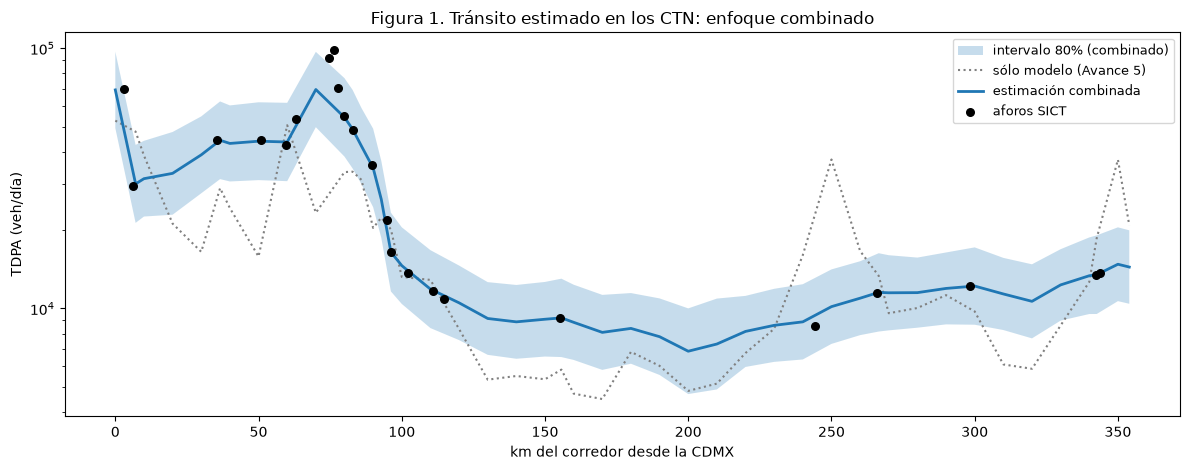

fuente_tdpa
aforo cercano (≤10 km)         31
hueco entre aforos (>10 km)    15
categoria
medio    31
alto     15


In [4]:
xc = ctn.chainage_km.to_numpy()
d = np.min(np.abs(xc[:, None] - x[None, :]), axis=1)
w = np.exp(-d / L_USO)
log_int = np.interp(xc, x, y)
log_ml, sig_ml = np.log(ctn.tdpa_estimado), (np.log(ctn.tdpa_p90) - np.log(ctn.tdpa_p10)) / (2 * 1.2816)
mu = w * log_int + (1 - w) * log_ml
sig = np.sqrt((w * SIG_INTERP) ** 2 + ((1 - w) * sig_ml) ** 2)
ctn["dist_aforo_km"], ctn["peso_aforos"] = d.round(1), w.round(2)
ctn["tdpa"], ctn["tdpa_p10c"], ctn["tdpa_p90c"] = np.exp(mu).round(0), np.exp(mu - 1.2816 * sig).round(0), np.exp(mu + 1.2816 * sig).round(0)
ctn["categoria"] = ETIQ[np.digitize(ctn.tdpa, CORTES)]
ctn["fuente_tdpa"] = np.where(d <= 10, "aforo cercano (≤10 km)", "hueco entre aforos (>10 km)")
ctn["ligeros_pct"] = np.interp(xc, x, af.ligeros_pct)
ctn["K_hora_pico"] = np.interp(xc, x, af.K.fillna(af.K.median()))

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.fill_between(xc, ctn.tdpa_p10c, ctn.tdpa_p90c, alpha=0.25, label="intervalo 80% (combinado)")
ax.plot(xc, ctn.tdpa_estimado, ":", color="gray", label="sólo modelo (Avance 5)")
ax.plot(xc, ctn.tdpa, "-", lw=2, label="estimación combinada")
ax.scatter(x, af.tdpa, color="black", zorder=5, s=30, label="aforos SICT")
ax.set_yscale("log"); ax.set(xlabel="km del corredor desde la CDMX", ylabel="TDPA (veh/día)", title="Figura 1. Tránsito estimado en los CTN: enfoque combinado")
ax.legend(fontsize=9); plt.tight_layout(); plt.savefig(OUT / "f1_movilidad_combinada.png", dpi=120); plt.show()
print(ctn.fuente_tdpa.value_counts().to_string()); print(ctn.categoria.value_counts().to_string())

## 3. Energía: demanda potencial de recarga y potencial solar
**Cadena de cálculo por CTN** (diaria, en kWh):

$$E = TDPA \times \%\text{ligeros} \times f_{VE} \times \ell_{tramo} \times c \times \varphi$$

| Parámetro | Valor (rango en sensibilidad) | Tipo | Respaldo |
|---|---|---|---|
| TDPA | estimación combinada (sección 2) | dato + modelo | SICT Datos Viales; modelo del Avance 5 |
| % ligeros | interpolado entre aforos | **dato oficial** | SICT Datos Viales (composición vehicular) |
| factor K | interpolado entre aforos | **dato oficial** | SICT Datos Viales (hora de máxima demanda) |
| $f_{VE}$ actual (2025) | calculado abajo: ≈1.3% en la ZMVM (rango 0.8% nacional – 2.3% CDMX) | **dato oficial** + proporción | INEGI, vehículos registrados 2025 por fuente de energía y entidad [1]; los híbridos conectables se estiman con la proporción conectables/eléctricos del Barómetro de EMA [2] |
| $f_{VE}$ medio | 5% | política oficial + ancla internacional | trayectoria de la ENME [3] (≈2029, cálculo propio con [1, 4]); coincide con el nivel actual de la flota mundial [5] |
| $f_{VE}$ alto | 15% | política oficial | misma trayectoria de la ENME [3] (≈2034, cálculo propio con [1, 4]) |
| $c$ | 0.20 kWh/km (0.15–0.25) | **literatura arbitrada** | consumo real medio de 0.183 kWh/km en 741 conductores, que aumenta a velocidad de autopista [6, 7] |
| $\varphi$ | 0.30 (0.12–0.50) | supuesto con piso | NREL supone 88% de recarga en casa (12% fuera) para todos los viajes [8]; en un corredor interurbano debe ser mayor |
| Cargador | 150 kW nominales | valor de literatura | potencia de carga rápida en corredores del análisis de NREL [8] |
| Potencia efectiva por posición | 60 kW | **dato de operación** | telemetría de 15.4 millones de sesiones en cargadores rápidos europeos: ≈60 kW promedio por sesión, sin importar la potencia nominal [9] |
| PR del sistema FV | 0.80 | valor de literatura | 14% de pérdidas por defecto de PVWatts más el inversor [10] |
| Coef. de temperatura | −0.4%/°C | valor de literatura | módulo estándar en PVWatts actualizado: −0.38%/°C [11] |
| Superficie FV | 25 m²/kWp (20–36) | valor de literatura | plantas reales en EE. UU.: 7.3–8.9 acres/MWac ≈ 30–36 m²/kW, con módulos de 2013 [12] |

**Tipos de respaldo:** *dato oficial* = INEGI, SICT o NASA; *dato de operación* = mediciones reales a gran escala; *literatura arbitrada* = revistas científicas; *valor de literatura* = laboratorios y herramientas de referencia (NREL); *política oficial* = metas del gobierno de México; *supuesto con piso* = decisión del equipo acotada por la literatura. **La trayectoria de la ENME es un cálculo propio** (ventas constantes de ≈1.5 millones de ligeros al año, rampa lineal hacia las metas, sin descontar bajas de la flota), y la ENME se publicó como anteproyecto en 2023. Las referencias numeradas están al final del notebook.

**Potencia y posiciones de carga:** la energía de la hora pico es $E \times K$; dividida entre la potencia efectiva medida por posición (60 kW) da el número de posiciones de carga rápida necesarias en esa hora.
**Potencial solar:** rendimiento FV = radiación (NASA POWER) × PR, con PR = 0.80 corregido por temperatura (−0.4%/°C sobre 25 °C de celda, con celda ≈ ambiente + 20 °C). Para dimensionar se usa la radiación de los días malos (percentil 10), así el sistema cubre la demanda casi todo el año. Superficie: 25 m² por kWp instalado en suelo.

> Todos los parámetros están en la celda siguiente y son fáciles de cambiar; el análisis de sensibilidad muestra cuál pesa más.

In [5]:
# Escenario ACTUAL desde los datos oficiales de INEGI (archivos exportados, sin modificar, en 01_RAW/inegi_vmrc)
import csv, io
def leer_inegi(path):
    for enc in ("utf-8", "latin-1"):
        try:
            texto = open(path, encoding=enc).read(); break
        except UnicodeDecodeError:
            continue
    return [[c.strip() for c in fila] for fila in csv.reader(io.StringIO(texto)) if any(c.strip() for c in fila)]
num = lambda v: 0.0 if v in ("-", "") else float(v.replace(",", ""))
RAW_VMRC = ROOT / "01_RAW" / "inegi_vmrc"

nac = leer_inegi(RAW_VMRC / "vmrc_2025_nacional_fuente_energia_por_clase.csv")
h = next(i for i, f in enumerate(nac) if "Automóviles" in f)
col = nac[h].index("Automóviles")
fila = {f[0]: f for f in nac[h + 1:] if f and f[0]}
autos_total, autos_elec = num(fila["Total"][col]), num(fila["Eléctrico"][col])
todas_total, todas_elec = num(fila["Total"][1]), num(fila["Eléctrico"][1])

est = leer_inegi(RAW_VMRC / "vmrc_2025_entidad_fuente_energia.csv")
h = next(i for i, f in enumerate(est) if "Eléctrico" in f and "Gasolina" in f)
ce, ct = est[h].index("Eléctrico"), est[h].index("Total")
estados = {f[1]: (num(f[ct]), num(f[ce])) for f in est[h + 1:] if len(f) > ce and f[0].isdigit()}

RATIO_PHEV_BEV = 105_506 / 104_565        # flota acumulada conectables / eléctricos al cierre de 2025 (EMA) [2]
AJUSTE_AUTOS = (autos_elec / todas_elec) / (autos_total / todas_total)   # la tabla por estado incluye todas las clases
def pct_recarga(total, elec):
    return elec * (1 + RATIO_PHEV_BEV) / total * AJUSTE_AUTOS

zmvm = [estados["Ciudad de México"], estados["México"]]
F_VE_ACTUAL = pct_recarga(sum(t for t, _ in zmvm), sum(e for _, e in zmvm))
F_VE_NACIONAL = autos_elec * (1 + RATIO_PHEV_BEV) / autos_total
F_VE_CDMX = pct_recarga(*estados["Ciudad de México"])
tabla_ve = pd.DataFrame({"referencia": ["Nacional (automóviles)", "ZMVM: CDMX + Estado de México", "Ciudad de México", "Morelos", "Guerrero"],
                         "pct_automoviles_con_recarga": [F_VE_NACIONAL, F_VE_ACTUAL, F_VE_CDMX,
                                                         pct_recarga(*estados["Morelos"]), pct_recarga(*estados["Guerrero"])]})
tabla_ve["pct_automoviles_con_recarga"] = (100 * tabla_ve.pct_automoviles_con_recarga).round(2)
display(tabla_ve)
print(f"Escenario actual del corredor (ZMVM): {100 * F_VE_ACTUAL:.1f}% | rango {100 * F_VE_NACIONAL:.1f}% (nacional) – {100 * F_VE_CDMX:.1f}% (CDMX)")

# Trayectoria de la ENME [3]: ventas cero emisiones de ~7% en 2025 [13] a 50% en 2030 y 100% en 2040 (cálculo ilustrativo)
VENTAS_LIGEROS = 146_724 / 0.097          # ventas anuales de ligeros ≈ electrificados 2025 / su participación [4]
flota_ve, tray = autos_elec * (1 + RATIO_PHEV_BEV), {}
for anio in range(2026, 2041):
    meta = 0.07 + 0.43 * min(anio - 2025, 5) / 5 if anio <= 2030 else 0.5 + 0.5 * (anio - 2030) / 10
    flota_ve += VENTAS_LIGEROS * meta
    tray[anio] = 100 * flota_ve / autos_total
ANIO_5 = next(a for a, v in tray.items() if v >= 5); ANIO_15 = next(a for a, v in tray.items() if v >= 15)
print(f"Con la trayectoria de la ENME, la flota nacional llegaría a 5% hacia {ANIO_5} y a 15% hacia {ANIO_15} "
      "(supone ventas constantes y no descuenta bajas)")

,referencia,pct_automoviles_con_recarga
0,Nacional (automóviles),0.77
1,ZMVM: CDMX + Estado de México,1.29
2,Ciudad de México,2.28
3,Morelos,0.40
4,Guerrero,0.23


Escenario actual del corredor (ZMVM): 1.3% | rango 0.8% (nacional) – 2.3% (CDMX)
Con la trayectoria de la ENME, la flota nacional llegaría a 5% hacia 2030 y a 15% hacia 2034 (supone ventas constantes y no descuenta bajas)


Rendimiento FV: 4.20–4.53 kWh/kWp/día (media anual); 3.55–3.78 en días malos (p10)


,kwh_dia_actual,cargadores_actual,kwp_fv_actual,ha_fv_actual,kwh_dia_medio,cargadores_medio,kwp_fv_medio,ha_fv_medio,kwh_dia_alto,cargadores_alto,kwp_fv_alto,ha_fv_alto,kwh_dia_medio_p10,kwh_dia_medio_p90
min,18.0,1.0,5.0,0.0,71.0,1.0,19.0,0.0,214.0,1.0,57.0,0.1,51.0,99.0
50%,64.5,1.0,17.5,0.0,250.5,1.0,68.0,0.2,751.5,2.0,204.0,0.5,179.5,348.0
max,493.0,1.0,130.0,0.3,1913.0,3.0,506.0,1.3,5738.0,8.0,1518.0,3.8,1370.0,2669.0


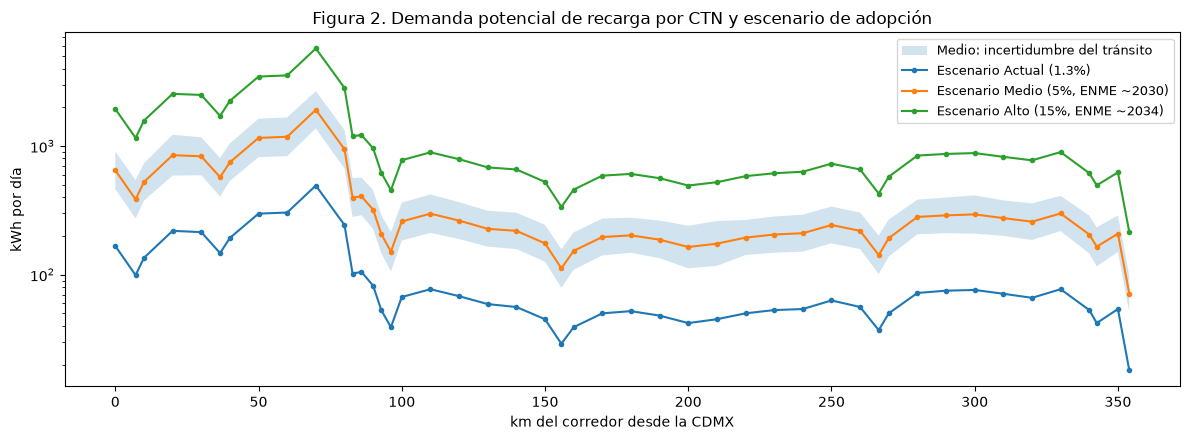

In [6]:
# Fuentes en la tabla de la sección 3 y en las referencias al final
ESCENARIOS_VE = {f"Actual ({100 * F_VE_ACTUAL:.1f}%)": F_VE_ACTUAL,          # INEGI [1] + EMA [2]
                 f"Medio (5%, ENME ~{ANIO_5})": 0.05,                    # [3, 5]
                 f"Alto (15%, ENME ~{ANIO_15})": 0.15}                   # [3]
CONSUMO_KWH_KM = 0.20      # [6, 7]
PHI = 0.30                 # piso 0.12 de NREL [8]; el valor central es supuesto del equipo
P_EFECTIVA_KW = 60         # potencia promedio medida por posición de carga rápida [9]
PR_BASE, COEF_T = 0.80, 0.004   # [10, 11]
M2_POR_KWP = 25            # [12]

orden = np.argsort(xc)
s_ord = xc[orden]
limites = np.r_[s_ord[0], (s_ord[:-1] + s_ord[1:]) / 2, s_ord[-1]]   # cada CTN atiende hasta la mitad del camino a sus vecinos
tramo = np.empty(len(xc)); tramo[orden] = np.diff(limites)
ctn["tramo_km"] = tramo.round(1)

pr = PR_BASE * (1 - COEF_T * np.clip(ctn.t2m_mean + 20 - 25, 0, None))
ctn["fv_kwh_kwp_dia"] = (ctn.allsky_sfc_sw_dwn_mean * pr).round(2)
ctn["fv_kwh_kwp_dia_p10"] = (ctn.allsky_sfc_sw_dwn_p10 * pr).round(2)
area_agri_1km_ha = (ctn.usv_agricola_riego_1km + ctn.usv_agricola_temporal_1km) / 100 * np.pi * 100   # ha en el círculo de 1 km

def demanda(tdpa, fve):
    return tdpa * ctn.ligeros_pct / 100 * fve * ctn.tramo_km * CONSUMO_KWH_KM * PHI

for nombre, fve in ESCENARIOS_VE.items():
    s = nombre.split(" ")[0].lower()
    e = demanda(ctn.tdpa, fve)
    ctn[f"kwh_dia_{s}"] = e.round(0)
    ctn[f"kw_pico_{s}"] = (e * ctn.K_hora_pico).round(0)
    ctn[f"cargadores_{s}"] = np.ceil(e * ctn.K_hora_pico / P_EFECTIVA_KW).astype(int)   # posiciones de carga
    ctn[f"kwp_fv_{s}"] = (e / ctn.fv_kwh_kwp_dia_p10).round(0)
    ctn[f"ha_fv_{s}"] = (ctn[f"kwp_fv_{s}"] * M2_POR_KWP / 1e4).round(2)
ctn["kwh_dia_medio_p10"], ctn["kwh_dia_medio_p90"] = demanda(ctn.tdpa_p10c, 0.05).round(0), demanda(ctn.tdpa_p90c, 0.05).round(0)
ctn["agri_1km_ha"] = area_agri_1km_ha.round(1)
ctn["fraccion_agri_para_fv"] = np.where(area_agri_1km_ha > 0, ctn.ha_fv_medio / area_agri_1km_ha, np.nan)

print(f"Rendimiento FV: {ctn.fv_kwh_kwp_dia.min():.2f}–{ctn.fv_kwh_kwp_dia.max():.2f} kWh/kWp/día (media anual); "
      f"{ctn.fv_kwh_kwp_dia_p10.min():.2f}–{ctn.fv_kwh_kwp_dia_p10.max():.2f} en días malos (p10)")
display(ctn[[c for c in ctn.columns if c.startswith(("kwh_dia_", "cargadores_", "kwp_fv_", "ha_fv_"))]].describe().loc[["min", "50%", "max"]].round(1))

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(xc, ctn.kwh_dia_medio_p10, ctn.kwh_dia_medio_p90, alpha=0.2, label="Medio: incertidumbre del tránsito")
for nombre in ESCENARIOS_VE:
    s = nombre.split(" ")[0].lower()
    ax.plot(xc, ctn[f"kwh_dia_{s}"], "-o", ms=3, label=f"Escenario {nombre}")
ax.set_yscale("log"); ax.set(xlabel="km del corredor desde la CDMX", ylabel="kWh por día", title="Figura 2. Demanda potencial de recarga por CTN y escenario de adopción")
ax.legend(fontsize=9); plt.tight_layout(); plt.savefig(OUT / "f2_demanda_energia.png", dpi=120); plt.show()

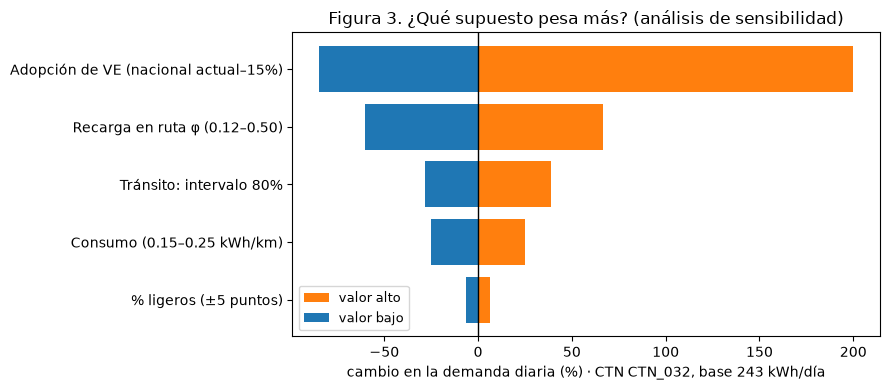

,supuesto,bajo_pct,alto_pct,rango
4,% ligeros (±5 puntos),-6.0,6.0,13.0
3,Consumo (0.15–0.25 kWh/km),-25.0,25.0,50.0
1,Tránsito: intervalo 80%,-28.0,39.0,67.0
2,Recarga en ruta φ (0.12–0.50),-60.0,67.0,127.0
0,Adopción de VE (nacional actual–15%),-85.0,200.0,285.0


In [7]:
# Sensibilidad: cuánto cambia la demanda del CTN mediano (escenario Medio) al mover cada supuesto en su rango
i = int((ctn.kwh_dia_medio - ctn.kwh_dia_medio.median()).abs().idxmin())
base = dict(tdpa=ctn.tdpa[i], lig=ctn.ligeros_pct[i] / 100, fve=0.05, tramo=ctn.tramo_km[i], c=CONSUMO_KWH_KM, phi=PHI)
E = lambda p: p["tdpa"] * p["lig"] * p["fve"] * p["tramo"] * p["c"] * p["phi"]
rangos = {"Adopción de VE (nacional actual–15%)": ("fve", F_VE_NACIONAL, 0.15),
          "Tránsito: intervalo 80%": ("tdpa", ctn.tdpa_p10c[i], ctn.tdpa_p90c[i]),
          "Recarga en ruta φ (0.12–0.50)": ("phi", 0.12, 0.50),
          "Consumo (0.15–0.25 kWh/km)": ("c", 0.15, 0.25),
          "% ligeros (±5 puntos)": ("lig", base["lig"] - 0.05, base["lig"] + 0.05)}
e0 = E(base); filas_s = []
for n, (k, lo, hi) in rangos.items():
    filas_s.append((n, 100 * (E({**base, k: lo}) / e0 - 1), 100 * (E({**base, k: hi}) / e0 - 1)))
sens = pd.DataFrame(filas_s, columns=["supuesto", "bajo_pct", "alto_pct"]).assign(rango=lambda t: t.alto_pct - t.bajo_pct).sort_values("rango")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(sens.supuesto, sens.alto_pct, color="tab:orange", label="valor alto"); ax.barh(sens.supuesto, sens.bajo_pct, color="tab:blue", label="valor bajo")
ax.axvline(0, color="k", lw=1); ax.set(xlabel=f"cambio en la demanda diaria (%) · CTN {ctn.ctn_id[i]}, base {e0:,.0f} kWh/día",
                                      title="Figura 3. ¿Qué supuesto pesa más? (análisis de sensibilidad)")
ax.legend(fontsize=9); plt.tight_layout(); plt.savefig(OUT / "f3_sensibilidad.png", dpi=120); plt.show()
display(sens.round(0))

## 4. Territorio
Del uso de suelo de INEGI (Serie VII, base 2018) se resumen, a 1 y 5 km de cada CTN: suelo **agrícola** (riego + temporal), **forestal** (bosque + selva), **urbano**, y la población a 10 km (Censo 2020).

In [8]:
for r in ["1km", "5km"]:
    ctn[f"agricola_{r}"] = ctn[f"usv_agricola_riego_{r}"] + ctn[f"usv_agricola_temporal_{r}"]
    ctn[f"forestal_{r}"] = ctn[f"usv_bosque_{r}"] + ctn[f"usv_selva_{r}"]
    ctn[f"urbano_{r}"] = ctn[f"usv_urbano_{r}"]
display(ctn[["agricola_5km", "forestal_5km", "urbano_5km", "pop_10km"]].describe().loc[["mean", "min", "50%", "max"]].round(1))
print("Uso de suelo en el punto exacto del CTN:", ctn.usv_clase_sitio.value_counts().to_dict())

,agricola_5km,forestal_5km,urbano_5km,pop_10km
mean,28.3,48.7,14.7,233889.0
min,0.0,0.0,0.0,2997.0
50%,24.4,56.5,4.4,38945.5
max,72.3,86.5,78.1,2421564.0


Uso de suelo en el punto exacto del CTN: {'agricola_temporal': 20, 'urbano': 8, 'bosque': 7, 'selva': 7, 'agricola_riego': 2, 'pastizal': 2}


## 5. Arquetipos de nodos
Se agrupan los CTN con **k-means** sobre variables estandarizadas de las tres dimensiones: tránsito (log), suelo agrícola, forestal y urbano a 5 km, y población a 10 km (log). La radiación solar **no se incluye** porque casi no varía a lo largo del corredor (todo el corredor tiene buen recurso), así que no distingue nodos. El número de grupos se elige con el coeficiente de silueta (3 a 6). Cada arquetipo se nombra con una regla fija: su entorno dominante (el uso de suelo con mayor valor estandarizado) y su nivel de tránsito.

Silueta por k: {3: 0.471, 4: 0.348, 5: 0.366, 6: 0.391} -> k = 3


,n_ctn,km_desde,km_hasta,tdpa_mediana,kwh_dia_medio,agricola_5km,forestal_5km,urbano_5km,pob_10km
arquetipo,,,,,,,,,
Periurbano · tránsito alto,8,0.0,354.0,36872.0,516.0,15.5,20.6,55.8,684802.5
Agrícola · tránsito alto,10,10.0,110.0,32294.5,358.5,57.7,17.3,14.5,137867.5
Montaña/forestal · tránsito medio,28,30.0,342.6,10583.5,207.5,21.5,67.9,3.0,14600.5


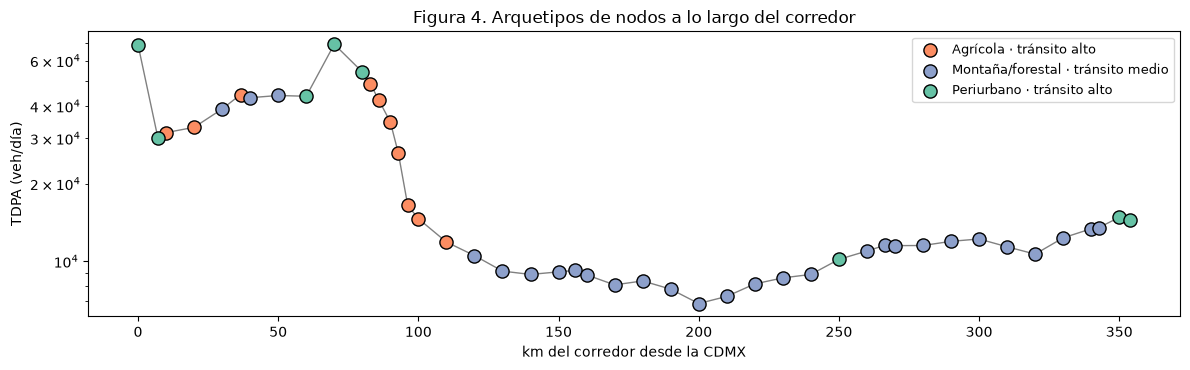

In [9]:
VARS = ["log_tdpa_c", "agricola_5km", "forestal_5km", "urbano_5km", "log_pop_10km"]
ctn["log_tdpa_c"], ctn["log_pop_10km"] = np.log(ctn.tdpa), np.log1p(ctn.pop_10km)
Z = StandardScaler().fit_transform(ctn[VARS])
sil = {k: silhouette_score(Z, KMeans(k, n_init=50, random_state=SEED).fit_predict(Z)) for k in range(3, 7)}
K_GRUPOS = max(sil, key=sil.get)
km = KMeans(K_GRUPOS, n_init=50, random_state=SEED).fit(Z)
ctn["grupo"] = km.labels_
cent = pd.DataFrame(km.cluster_centers_, columns=VARS)
ENTORNO = {"agricola_5km": "Agrícola", "forestal_5km": "Montaña/forestal", "urbano_5km": "Periurbano"}
nombres = {}
for g in range(K_GRUPOS):
    ent = ENTORNO[cent.loc[g, list(ENTORNO)].idxmax()]
    nivel = ETIQ[np.digitize(ctn.loc[ctn.grupo == g, "tdpa"].median(), CORTES)]
    nombres[g] = f"{ent} · tránsito {nivel}"
dup = pd.Series(nombres).duplicated(keep=False)
for g in range(K_GRUPOS):
    if dup[g]:
        nombres[g] += f" (km {ctn.loc[ctn.grupo == g, 'chainage_km'].min():.0f}–{ctn.loc[ctn.grupo == g, 'chainage_km'].max():.0f})"
ctn["arquetipo"] = ctn.grupo.map(nombres)
print("Silueta por k:", {k: round(v, 3) for k, v in sil.items()}, "-> k =", K_GRUPOS)
perfil = ctn.groupby("arquetipo").agg(n_ctn=("ctn_id", "size"), km_desde=("chainage_km", "min"), km_hasta=("chainage_km", "max"),
                                       tdpa_mediana=("tdpa", "median"), kwh_dia_medio=("kwh_dia_medio", "median"),
                                       agricola_5km=("agricola_5km", "mean"), forestal_5km=("forestal_5km", "mean"),
                                       urbano_5km=("urbano_5km", "mean"), pob_10km=("pop_10km", "median")).round(1).sort_values("km_desde")
display(perfil)

colores = dict(zip(perfil.index, plt.cm.Set2.colors))
fig, ax = plt.subplots(figsize=(12, 3.8))
for a, sub in ctn.groupby("arquetipo"):
    ax.scatter(sub.chainage_km, sub.tdpa, s=90, color=colores[a], edgecolor="k", label=a, zorder=3)
ax.plot(xc[orden], ctn.tdpa.to_numpy()[orden], color="gray", lw=1, zorder=1)
ax.set_yscale("log"); ax.set(xlabel="km del corredor desde la CDMX", ylabel="TDPA (veh/día)", title="Figura 4. Arquetipos de nodos a lo largo del corredor")
ax.legend(fontsize=9, loc="upper right"); plt.tight_layout(); plt.savefig(OUT / "f4_arquetipos.png", dpi=120); plt.show()

## 6. Coincidencias, tensiones y vacíos de información
El "éxito territorial" del sponsor es *detectar coincidencias, tensiones y vacíos de información entre dimensiones*. Se marcan con reglas simples y explícitas:
- **Oportunidad agrovoltaica (coincidencia):** ≥ 50% de suelo agrícola a 1 km y la superficie FV del escenario medio ocupa ≤ 5% de ese suelo agrícola.
- **Tensión ambiental:** ≥ 50% de bosque o selva a 1 km (posibles restricciones para construir).
- **Alta demanda en entorno forestal (tensión):** tránsito alto y tensión ambiental a la vez.
- **Vacío de información:** el CTN está a 20 km o más del aforo más cercano; ahí la estimación depende más de la interpolación en un hueco y del modelo, y un aforo nuevo reduciría más la incertidumbre (idea de *active learning* del sponsor).

,CTN
oportunidad_agrovoltaica,19
tension_ambiental,16
tension_demanda_forestal,3
vacio_informacion,6


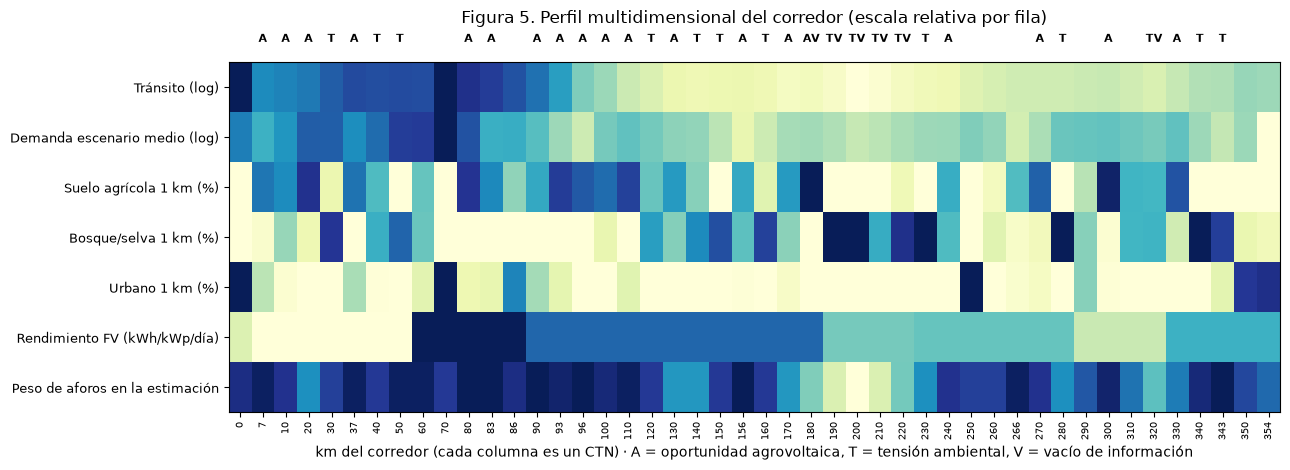

In [10]:
ctn["oportunidad_agrovoltaica"] = (ctn.agricola_1km >= 50) & (ctn.fraccion_agri_para_fv <= 0.05)
ctn["tension_ambiental"] = ctn.forestal_1km >= 50
ctn["tension_demanda_forestal"] = ctn.tension_ambiental & (ctn.categoria == "alto")
ctn["vacio_informacion"] = ctn.dist_aforo_km >= 20
banderas = ["oportunidad_agrovoltaica", "tension_ambiental", "tension_demanda_forestal", "vacio_informacion"]
display(ctn[banderas].sum().rename("CTN").to_frame())

filas_m = {"Tránsito (log)": np.log(ctn.tdpa), "Demanda escenario medio (log)": np.log1p(ctn.kwh_dia_medio),
           "Suelo agrícola 1 km (%)": ctn.agricola_1km, "Bosque/selva 1 km (%)": ctn.forestal_1km,
           "Urbano 1 km (%)": ctn.urbano_1km, "Rendimiento FV (kWh/kWp/día)": ctn.fv_kwh_kwp_dia,
           "Peso de aforos en la estimación": ctn.peso_aforos}
M = pd.DataFrame(filas_m).iloc[orden]
Mn = (M - M.min()) / (M.max() - M.min()).replace(0, 1)
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.imshow(Mn.T.to_numpy(), aspect="auto", cmap="YlGnBu")
ax.set_yticks(range(len(filas_m))); ax.set_yticklabels(filas_m.keys(), fontsize=9)
ax.set_xticks(range(len(ctn))); ax.set_xticklabels([f"{v:.0f}" for v in xc[orden]], fontsize=7, rotation=90)
for j, idx in enumerate(ctn.index[orden]):
    marcas = ("A" if ctn.oportunidad_agrovoltaica[idx] else "") + ("T" if ctn.tension_ambiental[idx] else "") + ("V" if ctn.vacio_informacion[idx] else "")
    ax.text(j, -0.9, marcas, ha="center", fontsize=8, fontweight="bold")
ax.set_xlabel("km del corredor (cada columna es un CTN) · A = oportunidad agrovoltaica, T = tensión ambiental, V = vacío de información")
ax.set_title("Figura 5. Perfil multidimensional del corredor (escala relativa por fila)", pad=28)
plt.tight_layout(); plt.savefig(OUT / "f5_perfil_multidimensional.png", dpi=120); plt.show()

In [11]:
cols = ["ctn_id", "chainage_km", "arquetipo", "tdpa", "tdpa_p10c", "tdpa_p90c", "categoria", "fuente_tdpa", "dist_aforo_km",
        "ligeros_pct", "K_hora_pico", "kwh_dia_actual", "kwh_dia_medio", "kwh_dia_alto", "cargadores_medio", "kwp_fv_medio",
        "ha_fv_medio", "fv_kwh_kwp_dia", "agricola_1km", "forestal_1km", "urbano_1km", "pop_10km", "usv_clase_sitio"] + banderas
final = ctn[cols].sort_values("chainage_km")
final.to_csv(OUT / "caracterizacion_ctn.csv", index=False, encoding="utf-8-sig")
perfil.to_csv(OUT / "arquetipos.csv", encoding="utf-8-sig")
display(final.head(12))

,ctn_id,chainage_km,arquetipo,tdpa,tdpa_p10c,tdpa_p90c,categoria,fuente_tdpa,dist_aforo_km,ligeros_pct,...,fv_kwh_kwp_dia,agricola_1km,forestal_1km,urbano_1km,pop_10km,usv_clase_sitio,oportunidad_agrovoltaica,tension_ambiental,tension_demanda_forestal,vacio_informacion
0,CTN_000,0.000,Periurbano · tránsito alto,69167.0,49341.0,96959.0,alto,aforo cercano (≤10 km),2.9,89.100000,...,4.26,0.000000,0.000000,99.560801,2421564.0,urbano,False,False,False,False
1,CTN_001,7.086,Periurbano · tránsito alto,30118.0,21330.0,42528.0,alto,aforo cercano (≤10 km),0.8,85.316035,...,4.20,68.674171,3.997110,27.168158,1183506.0,urbano,True,False,False,False
2,CTN_002,10.000,Agrícola · tránsito alto,31532.0,22557.0,44078.0,alto,aforo cercano (≤10 km),3.7,85.373456,...,4.20,63.351340,33.533182,2.954917,1193478.0,bosque,True,False,False,False
3,CTN_003,20.000,Agrícola · tránsito alto,33057.0,22926.0,47666.0,alto,hueco entre aforos (>10 km),13.7,85.570506,...,4.20,88.170281,11.669159,0.000000,140894.0,agricola_temporal,True,False,False,False
4,CTN_004,30.000,Montaña/forestal · tránsito medio,38936.0,27708.0,54715.0,alto,aforo cercano (≤10 km),5.4,85.767555,...,4.20,12.551255,87.288185,0.000000,26331.0,bosque,False,True,True,False
5,CTN_005,36.574,Agrícola · tránsito alto,44292.0,31409.0,62458.0,alto,aforo cercano (≤10 km),1.2,86.023182,...,4.20,69.795565,0.000000,30.043874,31400.0,urbano,True,False,False,False
6,CTN_006,40.000,Montaña/forestal · tránsito medio,43070.0,30765.0,60295.0,alto,aforo cercano (≤10 km),4.6,86.454612,...,4.20,47.092463,52.239642,0.507335,57862.0,bosque,False,True,True,False
7,CTN_007,50.000,Montaña/forestal · tránsito medio,43933.0,31135.0,61994.0,alto,aforo cercano (≤10 km),1.0,87.713896,...,4.20,0.000000,73.247817,0.000000,58883.0,bosque,False,True,True,False
8,CTN_008,60.000,Periurbano · tránsito alto,43626.0,30846.0,61700.0,alto,aforo cercano (≤10 km),0.4,90.174698,...,4.53,42.468068,41.345478,16.025893,420154.0,agricola_temporal,False,False,False,False
9,CTN_009,70.000,Periurbano · tránsito alto,69402.0,49731.0,96853.0,alto,aforo cercano (≤10 km),4.6,91.858326,...,4.53,0.000000,0.000000,99.839439,813108.0,urbano,False,False,False,False


## 7. Conclusiones
**Movilidad.** Combinar el modelo del Avance 5 con los 23 aforos del corredor reduce el error en el corredor de 0.66 (sólo modelo) a ≈0.29 en escala log (validación dejando un aforo fuera, L = 80 km). Con esta estimación, 15 CTN tienen tránsito alto y 31 medio; ninguno queda en la categoría baja: toda la MEX-095D es una autopista con flujo relevante. 31 CTN están a 10 km o menos de un aforo; los 6 más alejados (km 180–220 y km 320) forman el principal **vacío de información**.

**Energía.** Con parámetros respaldados en fuentes oficiales y literatura (sección 3), la demanda potencial de recarga en el corredor sería de ≈4.5 MWh/día con la adopción actual (≈1.3% de los automóviles de la ZMVM se recargan, según INEGI 2025), ≈17.6 MWh/día en el escenario medio (5%, que la trayectoria de la ENME alcanzaría hacia 2030) y ≈53 MWh/día en el escenario alto (15%, hacia 2034). En el escenario medio, cada CTN demandaría de ≈70 a ≈1,900 kWh/día (mediana ≈250); 37 de los 46 CTN necesitarían una sola posición de carga rápida en la hora pico y sólo 2 necesitarían tres, usando la potencia promedio medida en operación real (60 kW por sesión). El recurso solar es bueno y homogéneo (4.2–4.5 kWh/kWp/día de rendimiento medio, 3.6–3.8 en días malos) y el sistema FV para cubrir la demanda media ocupa como máximo ≈1.3 ha. **Los supuestos que más mueven el resultado son la adopción de vehículos eléctricos** (−85% a +200%) **y la fracción que se recarga en ruta** (−60% a +67%), ambos por encima de la incertidumbre del modelo de tránsito (−28% a +39%): son los datos que más conviene precisar con el sponsor.

**Territorio y arquetipos.** El corredor se organiza en tres arquetipos:
- **Periurbano · tránsito alto** (8 CTN, en la salida de la CDMX, Cuernavaca, Chilpancingo y Acapulco): la mayor demanda (mediana ≈775 kWh/día), entorno urbano, poco suelo libre.
- **Agrícola · tránsito alto** (10 CTN, km 10–110, valles de Morelos): alta demanda y ≈58% de suelo agrícola a 5 km; concentra la mitad de las oportunidades agrovoltaicas.
- **Montaña/forestal · tránsito medio** (28 CTN, la mayor parte del corredor): menor demanda y ≈68% de bosque o selva a 5 km; reúne todas las tensiones ambientales.

**Coincidencias, tensiones y vacíos** (el "éxito territorial" del sponsor):
- **19 CTN con oportunidad agrovoltaica:** ≥50% de suelo agrícola a 1 km y la superficie FV necesaria ocupa ≤5% de ese suelo.
- **16 CTN con tensión ambiental** (≥50% de bosque o selva a 1 km). Tres de ellos (km 30, 40 y 50, el tramo de Tres Marías) combinan **tránsito alto con entorno forestal**: alta necesidad de recarga donde construir es más delicado.
- **6 CTN en vacío de información:** un aforo nuevo en el tramo km 180–220 reduciría más la incertidumbre que cualquier mejora del modelo.

**Lo que esto no es.** Es una caracterización comparativa con supuestos explícitos, no una decisión de ubicación: la factibilidad legal, ambiental, social y de interconexión eléctrica requiere criterio de ingeniería y trabajo de campo.

**Siguientes pasos.** Acordar con el sponsor los escenarios de adopción y los parámetros de recarga; incorporar la red eléctrica (subestaciones y líneas) como restricción de interconexión; contrastar los arquetipos con el PTRF/TII; y transferir el método a un segundo corredor.

## Referencias de los parámetros
Consultadas en noviembre de 2026.

1. INEGI (2026). *Estadística de vehículos de motor registrados en circulación 2025*, por fuente de energía, clase de vehículo y entidad (cifras definitivas publicadas el 27 de agosto de 2026). Consulta interactiva: https://www.inegi.org.mx/sistemas/olap/Proyectos/bd/continuas/transporte/vehiculos.asp?s=est · Programa: https://www.inegi.org.mx/programas/vehiculosmotor/ · Archivos exportados, sin modificar, en `01_RAW/inegi_vmrc/`.
2. Electro Movilidad Asociación (2026). *Barómetro de la Electromovilidad 1T 2026*: flota acumulada al cierre de 2025 de 104,565 eléctricos y 105,506 híbridos conectables (marcas afiliadas). Cifras reportadas por DPL News: https://dplnews.com/vehiculos-electricos-hibridos-superan-235000-mexico/
3. SEMARNAT (2023). *Estrategia Nacional de Movilidad Eléctrica* (presentación oficial): https://www.gob.mx/cms/uploads/attachment/file/832517/2.3.ENME.pdf · Metas de 50% de ventas cero emisiones en 2030 y 100% en 2040, según DPL News: https://dplnews.com/?p=201011 . Publicada como anteproyecto; su versión final no se ha consolidado.
4. Participación de los vehículos electrificados en el mercado de ligeros (9.7% en 2025; 146,724 unidades), elaborada con datos de INEGI (RAIAVL). T-Research: https://www.tresearch.mx/post/venta-de-autos-electricos
5. IEA (2026). *Global EV Outlook 2026*. https://iea.blob.core.windows.net/assets/857aa690-2a43-453f-9f12-147cc8f0a1dd/GlobalEVOutlook2026.pdf
6. Fetene, G. M., Kaplan, S., Mabit, S. L., Jensen, A. F. y Prato, C. G. (2017). Harnessing big data for estimating the energy consumption and driving range of electric vehicles. *Transportation Research Part D*, 54, 1–11. https://doi.org/10.1016/j.trd.2017.04.013
7. Tollner, D. y Zöldy, M. *Investigating the Energetics of Electric Vehicles based on Real Measurements*. Acta Polytechnica Hungarica. https://acta.uni-obuda.hu/Tollner_Zoldy_147.pdf
8. Wood, E., Rames, C., Muratori, M., Raghavan, S. y Melaina, M. (2017). *National Plug-In Electric Vehicle Infrastructure Analysis*. NREL. https://www.nrel.gov/docs/fy17osti/69031.pdf
9. Chargalytics (2026). Telemetría de 15.4 millones de sesiones en cargadores rápidos (≥150 kW) de Noruega, Suecia, Países Bajos, Francia y Suiza, agosto–octubre de 2026; consistente con las cifras por sesión de los operadores Fastned e IONITY. https://www.chargalytics.com/deep-dives/why-faster-charging-isnt-the-answer/
10. Dobos, A. (2014). *PVWatts Version 5 Manual*. NREL/TP-6A20-62641. https://webarchive.library.unt.edu/web/20170124203116/http://www.nrel.gov/docs/fy14osti/62641.pdf
11. NREL (2019). Mejoras al modelo PVWatts (tipos de módulo y coeficientes de temperatura). https://nrel.gov/docs/fy19osti/74097.pdf
12. Ong, S., Campbell, C., Denholm, P., Margolis, R. y Heath, G. (2013). *Land-Use Requirements for Solar Power Plants in the United States*. NREL/TP-6A20-56290. https://www.nrel.gov/docs/fy13osti/56290.pdf
13. IEA (2026). *Global EV Outlook 2026 – Trends in electric cars* (participación de ventas en México mayor a 7% en 2025). https://www.iea.org/reports/global-ev-outlook-2026/trends-in-electric-cars

**Limitaciones de las fuentes:** el registro de INEGI agrupa a los híbridos conectables con los convencionales, por eso se usa la proporción de EMA (que sólo cubre marcas afiliadas); algunos estados reportan cifras incompletas de eléctricos e híbridos (por ejemplo, Puebla registra sólo 8 eléctricos), y el estado de registro no siempre es donde circula el vehículo. El ajuste de la tabla por estado a automóviles usa la proporción nacional. La trayectoria de la ENME es un cálculo propio ilustrativo, no un pronóstico.